In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

In [4]:
BASE='https://api.openf1.org/v1'
session_key=11377

# Sessions

In [3]:
params = {
    "year": 2026,
    "session_name": "Race",
}

response = requests.get(f'{BASE}/sessions', params=params)
response.raise_for_status()

data = response.json()

response.status_code

200

In [6]:
races=pd.DataFrame(data)

races.tail(10)

,session_key,session_type,session_name,date_start,date_end,meeting_key,circuit_key,circuit_short_name,country_key,country_code,country_name,location,gmt_offset,year,is_cancelled
15,11369,Race,Race,2026-09-13 13:00:00+00:00,2026-09-13T15:00:00+00:00,1294,153,Madring,1,ESP,Spain,Madrid,02:00:00,2026,False
16,11377,Race,Race,2026-09-26 11:00:00+00:00,2026-09-26T13:00:00+00:00,1295,144,Baku,30,AZE,Azerbaijan,Baku,04:00:00,2026,False
17,11731,Race,Race,2026-10-04 07:00:00+00:00,2026-10-04T09:00:00+00:00,1308,12,Kuala Lumpur,36,BRN,Bahrain,Kuala Lumpur,08:00:00,2026,False
18,11388,Race,Race,2026-10-11 12:00:00+00:00,2026-10-11T14:00:00+00:00,1296,61,Singapore,157,SGP,Singapore,Marina Bay,08:00:00,2026,False
19,11396,Race,Race,2026-10-25 20:00:00+00:00,2026-10-25T22:00:00+00:00,1297,9,Austin,19,USA,United States,Austin,-05:00:00,2026,False
20,11404,Race,Race,2026-11-01 20:00:00+00:00,2026-11-01T22:00:00+00:00,1298,65,Mexico City,8,MEX,Mexico,Mexico City,-06:00:00,2026,False
21,11412,Race,Race,2026-11-08 17:00:00+00:00,2026-11-08T19:00:00+00:00,1299,14,Interlagos,10,BRA,Brazil,São Paulo,-03:00:00,2026,False
22,11420,Race,Race,2026-11-22 04:00:00+00:00,2026-11-22T06:00:00+00:00,1300,152,Las Vegas,19,USA,United States,Las Vegas,-08:00:00,2026,False
23,11428,Race,Race,2026-11-29 16:00:00+00:00,2026-11-29T18:00:00+00:00,1301,150,Lusail,149,QAT,Qatar,Lusail,03:00:00,2026,False
24,11436,Race,Race,2026-12-06 13:00:00+00:00,2026-12-06T15:00:00+00:00,1302,70,Yas Marina Circuit,21,UAE,United Arab Emirates,Yas Marina,04:00:00,2026,False


In [15]:
races['date_start']=pd.to_datetime(races['date_start']).dt.tz_localize(None)
races['date_end']=pd.to_datetime(races['date_end']).dt.tz_localize(None)

# Sessions

In [19]:
drivers = requests.get(
    f"{BASE}/drivers",
    params={
        "session_key": session_key
    }
).json()

drivers_df = pd.DataFrame(drivers)

drivers_df.head(10)

,meeting_key,session_key,driver_number,broadcast_name,full_name,name_acronym,team_name,team_colour,first_name,last_name,headshot_url,country_code
0,1295,11377,1,L NORRIS,Lando NORRIS,NOR,McLaren,F47600,Lando,Norris,https://media.formula1.com/d_driver_fallback_i...,None
1,1295,11377,3,M VERSTAPPEN,Max VERSTAPPEN,VER,Red Bull Racing,4781D7,Max,Verstappen,https://media.formula1.com/d_driver_fallback_i...,None
2,1295,11377,5,G BORTOLETO,Gabriel BORTOLETO,BOR,Audi,F50537,Gabriel,Bortoleto,https://media.formula1.com/d_driver_fallback_i...,None
3,1295,11377,6,I HADJAR,Isack HADJAR,HAD,Red Bull Racing,4781D7,Isack,Hadjar,https://media.formula1.com/d_driver_fallback_i...,None
4,1295,11377,10,P GASLY,Pierre GASLY,GAS,Alpine,00A1E8,Pierre,Gasly,https://media.formula1.com/d_driver_fallback_i...,None
5,1295,11377,11,S PEREZ,Sergio PEREZ,PER,Cadillac,909090,Sergio,Perez,https://media.formula1.com/d_driver_fallback_i...,None
6,1295,11377,12,K ANTONELLI,Kimi ANTONELLI,ANT,Mercedes,00D7B6,Kimi,Antonelli,https://media.formula1.com/d_driver_fallback_i...,None
7,1295,11377,14,F ALONSO,Fernando ALONSO,ALO,Aston Martin,229971,Fernando,Alonso,https://media.formula1.com/d_driver_fallback_i...,None
8,1295,11377,16,C LECLERC,Charles LECLERC,LEC,Ferrari,ED1131,Charles,Leclerc,https://media.formula1.com/d_driver_fallback_i...,None
9,1295,11377,18,L STROLL,Lance STROLL,STR,Aston Martin,229971,Lance,Stroll,https://media.formula1.com/d_driver_fallback_i...,None


# Laps

In [21]:
laps = requests.get(
    f"{BASE}/laps",
    params={
        "session_key": session_key,
        "driver_number": 1,
    },
).json()

laps_df = pd.DataFrame(laps)
laps_df.head(5)

,meeting_key,session_key,driver_number,lap_number,date_start,duration_sector_1,duration_sector_2,duration_sector_3,i1_speed,i2_speed,is_pit_out_lap,lap_duration,segments_sector_1,segments_sector_2,segments_sector_3,st_speed
0,1295,11377,1,1,2026-09-26T11:03:50.711000+00:00,44.260,45.326,25.270,184.0,196.0,False,114.856,"[None, 2049, 2049, 2049, 2049, 2049, 2049, 2049]","[2049, 2049, 2049, 2049, 2049, 2051, 2049, 204...","[2049, 2049, 2049, 2049, 2049, 2049, 2049, 204...",328.0
1,1295,11377,1,2,2026-09-26T11:05:45.567000+00:00,39.575,45.259,25.368,183.0,198.0,False,110.202,"[2049, 2049, 2049, 2048, 2049, 2049, 2049, 2048]","[2049, 2048, 2049, 2049, 2049, 2049, 2049, 204...","[2048, 2048, 2048, 2051, 2048, 2048, 2048, 204...",323.0
2,1295,11377,1,3,2026-09-26T11:07:35.802000+00:00,40.277,45.170,25.472,177.0,205.0,False,110.919,"[2048, 2049, 2048, 2048, 2048, 2048, 2049, 2048]","[2048, 2048, 2049, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 2048]",325.0
3,1295,11377,1,4,2026-09-26T11:09:26.643000+00:00,39.242,44.847,25.388,185.0,200.0,False,109.477,"[None, 2049, 2049, 2048, 2048, 2049, 2049, 2049]","[2049, 2048, 2049, 2051, 2049, 2048, 2049, 204...","[2048, 2048, 2048, 2048, 2048, 2049, 2049, 204...",330.0
4,1295,11377,1,5,2026-09-26T11:11:16.231000+00:00,39.028,44.642,25.467,187.0,200.0,False,109.137,"[None, 2049, 2049, 2048, 2049, 2049, 2049, 2048]","[2049, 2048, 2049, 2048, 2048, 2048, 2048, 204...","[2048, 2048, 2048, 2048, 2048, 2048, 2048, 204...",327.0


In [22]:
laps_df['date_start']=pd.to_datetime(laps_df['date_start']).dt.tz_localize(None)

In [47]:
laps_df.shape

(36, 16)

# Car data

In [23]:
telemetry = requests.get(
    f"{BASE}/car_data",
    params={
        "session_key": session_key,
        "driver_number": 1,
    },
).json()

telemetry_df = pd.DataFrame(telemetry)
telemetry_df.head()

,date,session_key,meeting_key,speed,n_gear,throttle,brake,drs,driver_number,rpm
0,2026-09-25T13:08:13.100000+00:00,11377,1295,0,0,104,104,None,1,0
1,2026-09-25T13:08:13.340000+00:00,11377,1295,0,0,104,104,None,1,0
2,2026-09-25T13:08:13.620000+00:00,11377,1295,0,0,104,104,None,1,0
3,2026-09-25T13:08:13.820000+00:00,11377,1295,0,0,104,104,None,1,0
4,2026-09-26T10:06:59.668000+00:00,11377,1295,0,0,0,0,None,1,0


In [30]:
# telemetry_df['date']=pd.to_datetime(telemetry_df['date']).dt.tz_localize(None)
telemetry_df['date'] = pd.to_datetime(telemetry_df['date'], format='ISO8601').dt.tz_localize(None)

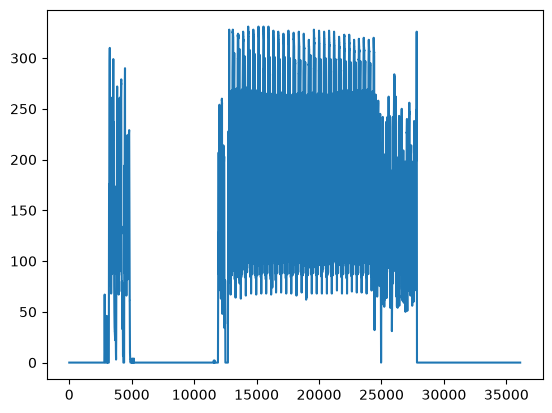

In [25]:
plt.plot(telemetry_df['speed'])
plt.show()

# Position

In [26]:
location = requests.get(
    f"{BASE}/location",
    params={
        "session_key": session_key,
        "driver_number": 1,
    },
).json()

location_df = pd.DataFrame(location)
location_df.head()

,date,session_key,y,meeting_key,x,z,driver_number
0,2026-09-25T13:08:13.175000+00:00,11377,-582,1295,786,-244,1
1,2026-09-25T13:08:13.475000+00:00,11377,-582,1295,786,-244,1
2,2026-09-25T13:08:13.835000+00:00,11377,-582,1295,786,-244,1
3,2026-09-26T10:07:03.290000+00:00,11377,0,1295,0,0,1
4,2026-09-26T10:07:03.450000+00:00,11377,0,1295,0,0,1


In [32]:
location_df['date'] = pd.to_datetime(location_df['date'], format='ISO8601').dt.tz_localize(None)

In [43]:
tyres =requests.get(
    f'{BASE}/stints',
    params={
        'session_key': session_key
    }
).json()

tyres_df=pd.DataFrame(tyres)
tyres_df.head()

,meeting_key,session_key,stint_number,driver_number,lap_start,lap_end,compound,tyre_age_at_start
0,1295,11377,1,18,1,7,SOFT,0
1,1295,11377,1,55,1,20,MEDIUM,0
2,1295,11377,1,14,1,20,SOFT,0
3,1295,11377,1,77,1,26,MEDIUM,0
4,1295,11377,1,23,1,29,SOFT,0


In [5]:
weather =requests.get(
    f'{BASE}/weather',
    params={
        'session_key': session_key
    }
).json()

weather_df=pd.DataFrame(weather)
weather_df.head()

,date,session_key,wind_direction,wind_speed,meeting_key,air_temperature,humidity,pressure,track_temperature,rainfall
0,2026-09-26T10:07:59.521000+00:00,11377,104,0.4,1295,26.2,59.2,1023.4,47.3,0
1,2026-09-26T10:08:59.521000+00:00,11377,337,0.7,1295,26.1,59.1,1023.1,48.1,0
2,2026-09-26T10:09:59.517000+00:00,11377,28,1.9,1295,26.1,60.0,1023.2,47.7,0
3,2026-09-26T10:10:59.531000+00:00,11377,165,0.5,1295,26.1,58.5,1023.2,46.6,0
4,2026-09-26T10:11:59.518000+00:00,11377,233,1.2,1295,26.2,58.6,1023.2,0.0,0


In [6]:
weather_df['date']=pd.to_datetime(weather_df['date']).dt.tz_localize(None)
weather_df

,date,session_key,wind_direction,wind_speed,meeting_key,air_temperature,humidity,pressure,track_temperature,rainfall
0,2026-09-26 10:07:59.521,11377,104,0.4,1295,26.2,59.2,1023.4,47.3,0
1,2026-09-26 10:08:59.521,11377,337,0.7,1295,26.1,59.1,1023.1,48.1,0
2,2026-09-26 10:09:59.517,11377,28,1.9,1295,26.1,60.0,1023.2,47.7,0
3,2026-09-26 10:10:59.531,11377,165,0.5,1295,26.1,58.5,1023.2,46.6,0
4,2026-09-26 10:11:59.518,11377,233,1.2,1295,26.2,58.6,1023.2,0.0,0
...,...,...,...,...,...,...,...,...,...,...
163,2026-09-26 12:51:00.039,11377,51,0.7,1295,26.3,41.2,1022.9,39.5,0
164,2026-09-26 12:52:00.050,11377,83,0.9,1295,26.2,41.4,1022.9,39.4,0
165,2026-09-26 12:53:00.075,11377,68,0.5,1295,26.3,40.7,1022.9,38.7,0
166,2026-09-26 12:54:00.066,11377,55,0.5,1295,26.4,41.0,1023.0,39.5,0


In [46]:
weather_df.shape

(168, 10)

# Analysis

In [42]:
lap_number=1

lap_start=laps_df.loc[lap_number-1]['date_start']
lap_end=laps_df.loc[lap_number]['date_start']

lap_telemetry=telemetry_df[(lap_start<=telemetry_df['date']) & (telemetry_df['date']<=lap_end)]

lap_telemetry.head()

,date,session_key,meeting_key,speed,n_gear,throttle,brake,drs,driver_number,rpm
12705,2026-09-26 11:03:50.921,11377,1295,0,1,28,100,None,1,12291
12706,2026-09-26 11:03:51.361,11377,1295,10,1,27,0,None,1,9955
12707,2026-09-26 11:03:51.561,11377,1295,16,1,26,0,None,1,8555
12708,2026-09-26 11:03:51.761,11377,1295,23,1,27,0,None,1,7155
12709,2026-09-26 11:03:52.041,11377,1295,32,1,29,0,None,1,6090


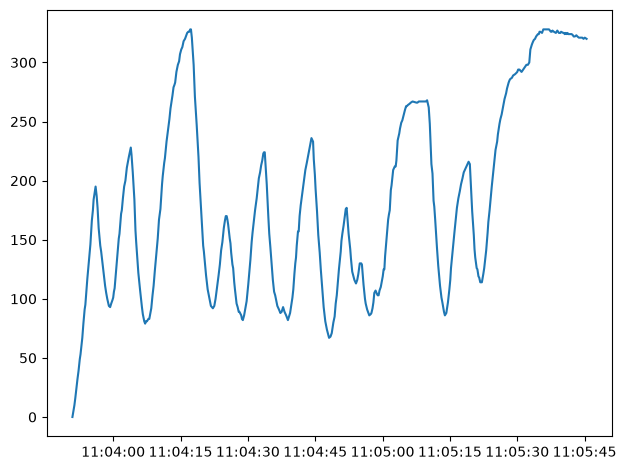

In [44]:
plt.plot(lap_telemetry['date'], lap_telemetry['speed'])
# plt.plot(lap_telemetry['date'], lap_telemetry['rpm'])
plt.tight_layout()
plt.show()

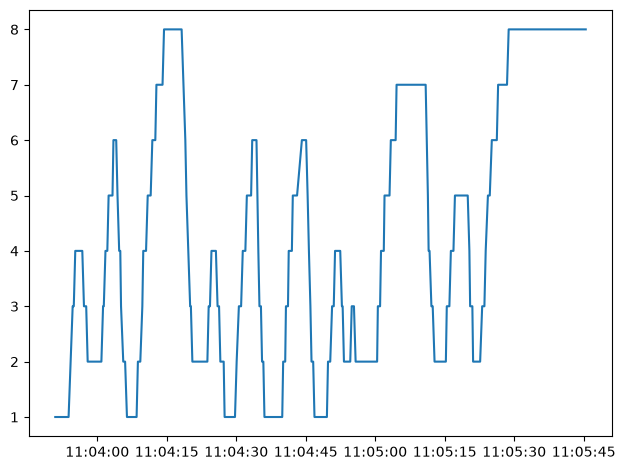

In [51]:
plt.plot(lap_telemetry['date'], lap_telemetry['n_gear'])
plt.tight_layout()
plt.show()

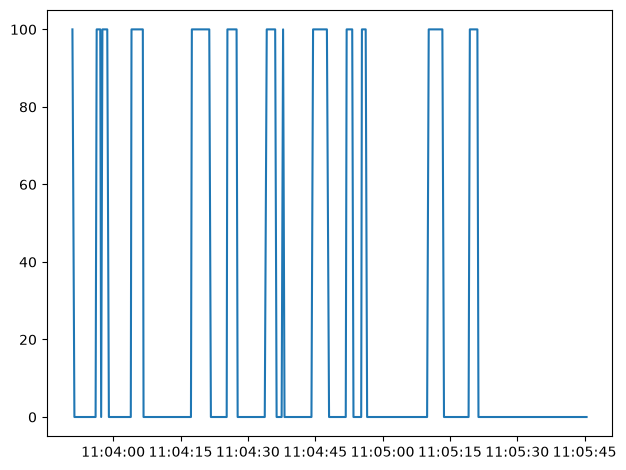

In [58]:
plt.plot(lap_telemetry['date'], lap_telemetry['brake'])
plt.tight_layout()
plt.show()

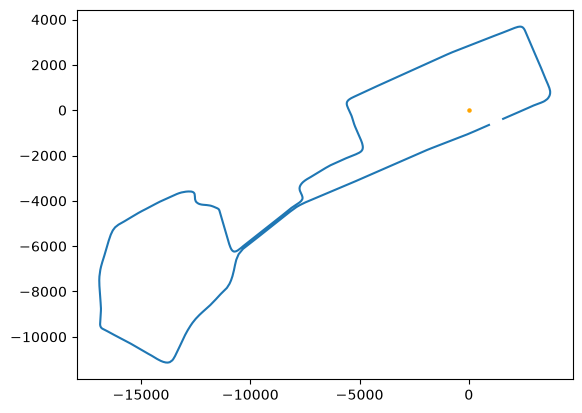

In [57]:
lap_pos=location_df[(lap_start<=location_df['date']) & (location_df['date']<lap_end)]

plt.plot(lap_pos['x'], lap_pos['y'])
plt.scatter([0], [0], s=5, c='orange')
plt.show()

# Lets think about how to compare i

## Full pipeline

In [3]:
session_key=11377
driver_number=12

BASE='https://api.openf1.org/v1'

In [21]:
import requests
import pandas as pd

def get_laps_df(session_key, driver_number):
    laps = requests.get(
    f"{BASE}/laps",
    params={
        "session_key": session_key,
        "driver_number": driver_number,
        },
    ).json()

    data= pd.DataFrame(laps)
    data['date_start']=pd.to_datetime(data['date_start']).dt.tz_localize(None)
    return data


def get_telemetry(session_key, driver_number):
    telemetry = requests.get(
    f"{BASE}/car_data",
    params={
        "session_key": session_key,
        "driver_number": driver_number,
        },
    ).json()

    data= pd.DataFrame(telemetry)
    data['date'] = pd.to_datetime(data['date'], format='ISO8601').dt.tz_localize(None)
    return data


def car_data(session_key, driver_number):
    location = requests.get(
        f"{BASE}/location",
        params={
            "session_key": session_key,
            "driver_number": driver_number,
        },
    ).json()

    data = pd.DataFrame(location)
    data['date'] = pd.to_datetime(data['date'], format='ISO8601').dt.tz_localize(None)
    return data

In [22]:
laps_df=get_laps_df(session_key, driver_number)
telemetry_df=get_telemetry(session_key, driver_number)
position_df=car_data(session_key,driver_number)

In [23]:
lap_number=20

lap_start=laps_df.loc[lap_number-1]['date_start']
lap_end=laps_df.loc[lap_number]['date_start']

lap_telemetry=telemetry_df[(lap_start<=telemetry_df['date']) & (telemetry_df['date']<=lap_end)]
lap_pos=position_df[(lap_start<=position_df['date']) & (position_df['date']<lap_end)]

In [28]:
lap_telemetry.tail()

,date,session_key,meeting_key,speed,n_gear,throttle,brake,drs,driver_number,rpm
20874,2026-09-26 11:40:23.369,11377,1295,318,8,100,0,None,12,10920
20875,2026-09-26 11:40:23.769,11377,1295,317,8,100,0,None,12,10921
20876,2026-09-26 11:40:24.169,11377,1295,318,8,100,0,None,12,10899
20877,2026-09-26 11:40:24.329,11377,1295,317,8,100,0,None,12,10916
20878,2026-09-26 11:40:24.649,11377,1295,318,8,100,0,None,12,10947


In [29]:
lap_telemetry.shape

(402, 10)

In [27]:
lap_pos.tail()

,date,session_key,y,meeting_key,x,z,driver_number
21336,2026-09-26 11:40:23.415,11377,-992,1295,114,-245,12
21337,2026-09-26 11:40:23.575,11377,-904,1295,322,-247,12
21338,2026-09-26 11:40:24.015,11377,-735,1295,720,-246,12
21339,2026-09-26 11:40:24.295,11377,-681,1295,849,-246,12
21340,2026-09-26 11:40:24.655,11377,-525,1295,1224,-245,12


In [30]:
lap_pos.shape

(411, 7)

In [35]:
import numpy as np

telemetry = lap_telemetry.sort_values("date").copy()
position = lap_pos.sort_values("date").copy()

t_tel = telemetry["date"].astype("int64")
t_pos = position["date"].astype("int64")

telemetry["x"] = np.interp(
    t_tel,
    t_pos,
    position["x"]
)

telemetry["y"] = np.interp(
    t_tel,
    t_pos,
    position["y"]
)

telemetry["z"] = np.interp(
    t_tel,
    t_pos,
    position["z"]
)

In [38]:
telemetry.head()

,date,session_key,meeting_key,speed,n_gear,throttle,brake,drs,driver_number,rpm,x,y,z
20477,2026-09-26 11:38:36.729,11377,1295,316,8,100,0,None,12,10884,1336.000000,-479.000000,-245.000000
20478,2026-09-26 11:38:37.049,11377,1295,315,8,100,0,None,12,10874,1475.749862,-420.500058,-244.458334
20479,2026-09-26 11:38:37.489,11377,1295,315,8,100,0,None,12,10833,1815.569897,-277.840044,-243.000000
20480,2026-09-26 11:38:37.889,11377,1295,314,8,100,0,None,12,10809,2136.869897,-143.110043,-243.000000
20481,2026-09-26 11:38:38.209,11377,1295,314,8,100,0,None,12,10796,2394.893230,-35.486710,-243.000000


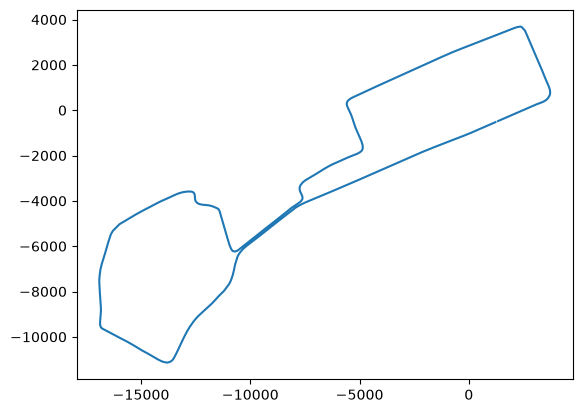

In [42]:
plt.plot(telemetry['x'], telemetry['y'])
plt.show()